In [1]:
# Model 2 Training - Imports

import os
import random
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision.transforms as transforms
from torchvision import datasets, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
)

from tqdm.auto import tqdm

c:\Users\Ankit Bhadra\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Configuration

SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 64
EPOCHS = 30
LEARNING_RATE = 1e-4

TRAIN_DIR = "model2_data/train"
VALID_DIR = "model2_data/valid"
TEST_DIR = "model2_data/test"

CHECKPOINT_DIR = "checkpoints"
OUTPUT_DIR = "outputs"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)


# Reproducibility

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)
random.seed(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# Device

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [3]:
# Data Transforms

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

valid_test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [4]:
# Load Datasets

train_dataset = datasets.ImageFolder(
    root=TRAIN_DIR,
    transform=train_transform
)

valid_dataset = datasets.ImageFolder(
    root=VALID_DIR,
    transform=valid_test_transform
)

test_dataset = datasets.ImageFolder(
    root=TEST_DIR,
    transform=valid_test_transform
)


# Create DataLoaders

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=8,
    pin_memory=True,
    persistent_workers=True
)


print(f"Training Images   : {len(train_dataset)}")
print(f"Validation Images : {len(valid_dataset)}")
print(f"Test Images       : {len(test_dataset)}")

print("\nClasses:", train_dataset.classes)

Training Images   : 52376
Validation Images : 14969
Test Images       : 7481

Classes: ['Mild Demented', 'Non Demented', 'Very Mild Demented']


In [5]:
# Class Distribution

class_counts = Counter(train_dataset.targets)

print("Training Set Class Distribution:")

for class_name, class_index in train_dataset.class_to_idx.items():
    print(f"{class_name:<20}: {class_counts[class_index]}")


# Compute Class Weights

total_samples = len(train_dataset)

class_weights = [
    total_samples / class_counts[i]
    for i in range(len(train_dataset.classes))
]

class_weights = torch.tensor(class_weights, dtype=torch.float32).to(device)

print("\nClass Weights:")
print(class_weights)

Training Set Class Distribution:
Mild Demented       : 16805
Non Demented        : 12596
Very Mild Demented  : 22975

Class Weights:
tensor([3.1167, 4.1581, 2.2797], device='cuda:0')


In [6]:
# Load Pretrained ResNet18

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)


# Replace the Final Classification Layer

num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(train_dataset.classes))


# Freeze All Layers

for param in model.parameters():
    param.requires_grad = False


# Unfreeze Layer 3

for param in model.layer3.parameters():
    param.requires_grad = True


# Unfreeze Layer 4

for param in model.layer4.parameters():
    param.requires_grad = True


# Unfreeze Final Fully Connected Layer

for param in model.fc.parameters():
    param.requires_grad = True


model = model.to(device)


# Display Model Information

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Trainable Parameters : {trainable_params:,}")
print(f"Total Parameters     : {total_params:,}")

print("\nModel Ready!")

Trainable Parameters : 10,494,979
Total Parameters     : 11,178,051

Model Ready!


In [7]:
# Loss Function

criterion = nn.CrossEntropyLoss(weight=class_weights)


# Optimizer

optimizer = optim.Adam(
    list(model.layer3.parameters()) +
    list(model.layer4.parameters()) +
    list(model.fc.parameters()),
    lr=LEARNING_RATE
)

print("Loss Function and Optimizer Ready!")

Loss Function and Optimizer Ready!


In [8]:
# Learning Rate Scheduler

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2
)


# Early Stopping

EARLY_STOPPING_PATIENCE = 5

best_val_loss = float("inf")
best_val_accuracy = 0.0

epochs_without_improvement = 0


# Training History

train_losses = []
valid_losses = []

train_accuracies = []
valid_accuracies = []

print("Training Utilities Ready!")

Training Utilities Ready!


In [9]:
# Training Loop

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")

    # Training

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    train_bar = tqdm(train_loader, desc="Training", leave=False)

    for images, labels in train_bar:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        train_bar.set_postfix(loss=f"{loss.item():.4f}")

    train_loss = running_loss / len(train_dataset)
    train_accuracy = 100 * correct / total

    # Validation

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        valid_bar = tqdm(valid_loader, desc="Validation", leave=False)

        for images, labels in valid_bar:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            valid_bar.set_postfix(loss=f"{loss.item():.4f}")

    valid_loss = running_loss / len(valid_dataset)
    valid_accuracy = 100 * correct / total

    # Save Training History

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    train_accuracies.append(train_accuracy)
    valid_accuracies.append(valid_accuracy)

    # Update Learning Rate

    scheduler.step(valid_loss)

    # Save Best Model

    if valid_loss < best_val_loss:

        best_val_loss = valid_loss
        best_val_accuracy = valid_accuracy

        torch.save(
            model.state_dict(),
            os.path.join(
                CHECKPOINT_DIR,
                "best_model2.pth"
            )
        )

        epochs_without_improvement = 0

        print("Best model saved!")

    else:

        epochs_without_improvement += 1

    # Print Metrics

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Loss: {valid_loss:.4f} | "
        f"Val Acc: {valid_accuracy:.2f}% | "
        f"LR: {current_lr:.6f}"
    )

    # Early Stopping

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:

        print("\nEarly stopping triggered!")

        break


Epoch [1/30]


Best model saved!
Train Loss: 0.2756 | Train Acc: 87.81% | Val Loss: 0.1023 | Val Acc: 95.96% | LR: 0.000100

Epoch [2/30]


Best model saved!
Train Loss: 0.0874 | Train Acc: 96.58% | Val Loss: 0.0481 | Val Acc: 98.14% | LR: 0.000100

Epoch [3/30]


Best model saved!
Train Loss: 0.0459 | Train Acc: 98.25% | Val Loss: 0.0292 | Val Acc: 98.86% | LR: 0.000100

Epoch [4/30]


Best model saved!
Train Loss: 0.0314 | Train Acc: 98.88% | Val Loss: 0.0207 | Val Acc: 99.33% | LR: 0.000100

Epoch [5/30]


...

Train Loss: 0.0006 | Train Acc: 99.98% | Val Loss: 0.0015 | Val Acc: 99.96% | LR: 0.000025

Epoch [27/30]


Train Loss: 0.0006 | Train Acc: 99.98% | Val Loss: 0.0009 | Val Acc: 99.97% | LR: 0.000013

Epoch [28/30]


Train Loss: 0.0004 | Train Acc: 99.99% | Val Loss: 0.0003 | Val Acc: 99.98% | LR: 0.000013

Epoch [29/30]


Best model saved!
Train Loss: 0.0003 | Train Acc: 99.99% | Val Loss: 0.0001 | Val Acc: 99.99% | LR: 0.000013

Epoch [30/30]


Best model saved!
Train Loss: 0.0002 | Train Acc: 100.00% | Val Loss: 0.0000 | Val Acc: 100.00% | LR: 0.000013


Test Loss     : 0.0000
Test Accuracy : 100.00%
                    precision    recall  f1-score   support

     Mild Demented     1.0000    1.0000    1.0000      2410
      Non Demented     1.0000    1.0000    1.0000      1737
Very Mild Demented     1.0000    1.0000    1.0000      3334

          accuracy                         1.0000      7481
         macro avg     1.0000    1.0000    1.0000      7481
      weighted avg     1.0000    1.0000    1.0000      7481



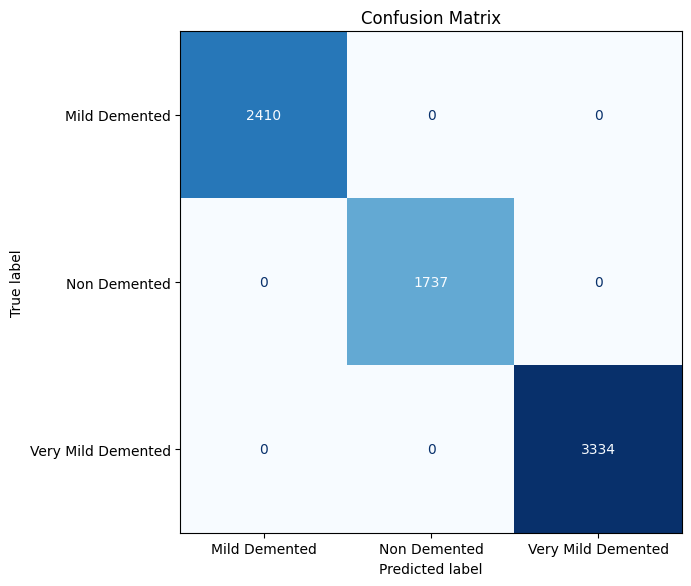

In [15]:
# Evaluate on official test set

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
import matplotlib.pyplot as plt
import pandas as pd
import torch

# Load best model
import os

best_model_path = os.path.join(CHECKPOINT_DIR, "best_model2.pth")

model.load_state_dict(torch.load(best_model_path, map_location=device))
model.eval()
model.eval()

test_loss = 0
correct = 0
total = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item()

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()
        total += labels.size(0)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

test_acc = 100 * correct / total
test_loss /= len(test_loader)

print("=" * 60)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.2f}%")
print("=" * 60)

# Classification report
report = classification_report(
    all_labels,
    all_preds,
    target_names=test_dataset.classes,
    digits=4,
)

print(report)

import os

with open(os.path.join(OUTPUT_DIR, "classification_report.txt"), "w") as f:
    f.write(report)

# Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes,
)

fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Confusion Matrix")
plt.tight_layout()

plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"))
plt.show()

In [16]:
import json
import os
import torch

os.makedirs("model2_export", exist_ok=True)

# Save weights
torch.save(model.state_dict(), "model2_export/model2_best.pth")

# Save complete checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "classes": test_dataset.classes,
    "image_size": IMAGE_SIZE,
    "architecture": "ResNet18",
    "num_classes": len(test_dataset.classes),
}, "model2_export/model2_checkpoint.pt")

# Save class names
with open("model2_export/classes.json", "w") as f:
    json.dump(test_dataset.classes, f, indent=4)

print("✓ Model exported successfully.")

✓ Model exported successfully.
